In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np

# Load once
data = pd.read_csv("/content/drive/MyDrive/Veritas-Eshav2/bb-ecDNA-master-table.tsv", sep="\t")

# Basic features
df = data.copy()
df["TCN"] = df["clone_nMaj"] + df["clone_nMin"]
df["size"] = df["endpos"] - df["startpos"]

# Optional: convert size to Mb if you need it
df["size_MB"] = df["size"] / 1_000_000

# Strip 'chr' prefix and keep only autosomes
df["#chr"] = df["#chr"].str.replace("chr", "", regex=False)
df = df[~df["#chr"].isin(["X", "Y"])]
df["#chr"] = df["#chr"].astype(int)

# Drop rows missing key features
df = df.dropna(subset=["LogR", "BAF", "TCN", "size"])
df = df.reset_index(drop=True)


In [3]:
# Sort per sample and chromosome
samples = []
for bb_id in df["BB_ID"].unique():
    sample_df = df[df["BB_ID"] == bb_id].copy()
    sample_df = sample_df.sort_values(["#chr", "startpos"]).reset_index(drop=True)

    # TCN_diff
    tcn_diff = sample_df["TCN"].diff().fillna(sample_df["TCN"]).abs()

    # BAF_diff
    baf_diff = sample_df["BAF"].diff().fillna(sample_df["BAF"]).abs()

    sample_df["TCN_diff"] = tcn_diff
    sample_df["BAF_diff"] = baf_diff
    samples.append(sample_df)

result_df = pd.concat(samples, ignore_index=True)

# Binary label
result_df["Classification_binary"] = (result_df["Classification"] == "ecDNA").astype(int)


In [18]:
feature_cols = ["size", "BAF_diff", "TCN_diff"]
X = result_df[feature_cols].values
y = result_df["Classification_binary"].values

In [19]:
from sklearn.utils import resample

ec = result_df[result_df["Classification_binary"] == 1]
non_ec = result_df[result_df["Classification_binary"] == 0]

ec_resampled = resample(ec, replace=True, n_samples=len(non_ec), random_state=25)
data_oversampled = pd.concat([non_ec, ec_resampled], ignore_index=True)

X_os = data_oversampled[feature_cols].values
y_os = data_oversampled["Classification_binary"].values


Fold 1
AUC: 0.9756318487097915
Accuracy: 0.9881968859869412
Confusion matrix:
 [[3932    4]
 [  43    3]]
              precision    recall  f1-score   support

   non-ecDNA       0.99      1.00      0.99      3936
       ecDNA       0.43      0.07      0.11        46

    accuracy                           0.99      3982
   macro avg       0.71      0.53      0.55      3982
weighted avg       0.98      0.99      0.98      3982


Fold 2
AUC: 0.9873151477466273
Accuracy: 0.9892014063284782
Confusion matrix:
 [[3925   10]
 [  33   14]]
              precision    recall  f1-score   support

   non-ecDNA       0.99      1.00      0.99      3935
       ecDNA       0.58      0.30      0.39        47

    accuracy                           0.99      3982
   macro avg       0.79      0.65      0.69      3982
weighted avg       0.99      0.99      0.99      3982


Fold 3
AUC: 0.9844061748087269
Accuracy: 0.988950276243094
Confusion matrix:
 [[3929    6]
 [  38    9]]
              precision   

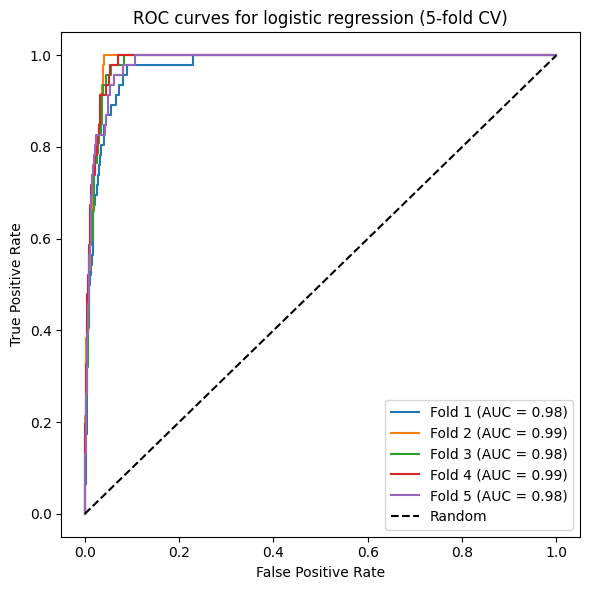

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_curve, auc, confusion_matrix, classification_report, accuracy_score
import numpy as np
import matplotlib.pyplot as plt

k = 5
skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

logreg = LogisticRegression(max_iter=1000)

auc_scores = []
all_conf = []
fprs = []
tprs = []

for fold, (train_idx, test_idx) in enumerate(skf.split(X, y), start=1):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    logreg.fit(X_train, y_train)
    y_prob = logreg.predict_proba(X_test)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    fold_auc = auc(fpr, tpr)
    auc_scores.append(fold_auc)
    fprs.append(fpr)
    tprs.append(tpr)

    cm = confusion_matrix(y_test, y_pred)
    all_conf.append(cm)

    print(f"\nFold {fold}")
    print("AUC:", fold_auc)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Confusion matrix:\n", cm)
    print(classification_report(y_test, y_pred, target_names=["non-ecDNA", "ecDNA"]))

print("\nMean AUC:", np.mean(auc_scores))

# Plot ROC for each fold
plt.figure(figsize=(6, 6))
for i, (fpr, tpr) in enumerate(zip(fprs, tprs), start=1):
    plt.plot(fpr, tpr, label=f"Fold {i} (AUC = {auc_scores[i-1]:.2f})")

plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curves for logistic regression (5-fold CV)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Confusion matrix across all folds:
 [[19654    22]
 [  228     4]]


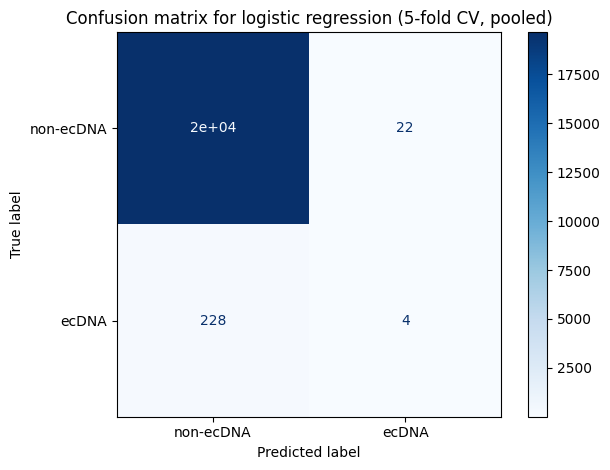

In [15]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Re-run the loop but store all predictions
all_y_true = []
all_y_pred = []

for fold, (train_idx, test_idx) in enumerate(skf.split(X, y), start=1):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    logreg.fit(X_train, y_train)
    y_prob = logreg.predict_proba(X_test)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)

    all_y_true.append(y_test)
    all_y_pred.append(y_pred)

# concatenate across folds
all_y_true = np.concatenate(all_y_true)
all_y_pred = np.concatenate(all_y_pred)

cm_total = confusion_matrix(all_y_true, all_y_pred)
print("Confusion matrix across all folds:\n", cm_total)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_total,
                              display_labels=["non-ecDNA", "ecDNA"])
disp.plot(cmap="Blues")
plt.title("Confusion matrix for logistic regression (5-fold CV, pooled)")
plt.tight_layout()
plt.show()


In [12]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)

auc_scores_rf = []

for fold, (train_idx, test_idx) in enumerate(skf.split(X, y), start=1):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    rf.fit(X_train, y_train)
    y_prob = rf.predict_proba(X_test)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    fold_auc = auc(fpr, tpr)
    auc_scores_rf.append(fold_auc)

    cm = confusion_matrix(y_test, y_pred)
    all_conf.append(cm)

    print(f"\nFold {fold}")
    print("AUC:", fold_auc)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Confusion matrix:\n", cm)
    print(classification_report(y_test, y_pred, target_names=["non-ecDNA", "ecDNA"]))

print("\nMean AUC:", np.mean(auc_scores))


Fold 1
AUC: 0.9035850786496995
Accuracy: 0.9869412355600201
Confusion matrix:
 [[3926   10]
 [  42    4]]
              precision    recall  f1-score   support

   non-ecDNA       0.99      1.00      0.99      3936
       ecDNA       0.29      0.09      0.13        46

    accuracy                           0.99      3982
   macro avg       0.64      0.54      0.56      3982
weighted avg       0.98      0.99      0.98      3982


Fold 2
AUC: 0.9620265484333179
Accuracy: 0.9869412355600201
Confusion matrix:
 [[3926    9]
 [  43    4]]
              precision    recall  f1-score   support

   non-ecDNA       0.99      1.00      0.99      3935
       ecDNA       0.31      0.09      0.13        47

    accuracy                           0.99      3982
   macro avg       0.65      0.54      0.56      3982
weighted avg       0.98      0.99      0.98      3982


Fold 3
AUC: 0.930579361431777
Accuracy: 0.9874434957307886
Confusion matrix:
 [[3926    9]
 [  41    6]]
              precision   

In [13]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

def build_nn(input_dim):
    model = Sequential()
    model.add(Dense(64, activation="relu", input_dim=input_dim))
    model.add(Dense(1, activation="sigmoid"))
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model

auc_scores_nn = []

for fold, (train_idx, test_idx) in enumerate(skf.split(X, y), start=1):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    nn = build_nn(X_train.shape[1])
    nn.fit(X_train, y_train, epochs=10, batch_size=32, verbose=0)

    y_prob = nn.predict(X_test).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    fold_auc = auc(fpr, tpr)
    auc_scores_nn.append(fold_auc)

    cm = confusion_matrix(y_test, y_pred)
    all_conf.append(cm)

    print(f"\nFold {fold}")
    print("AUC:", fold_auc)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Confusion matrix:\n", cm)
    print(classification_report(y_test, y_pred, target_names=["non-ecDNA", "ecDNA"]))

print("\nMean AUC:", np.mean(auc_scores))


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

Fold 1
AUC: 0.4973323170731707
Accuracy: 0.9876946258161727
Confusion matrix:
 [[3933    3]
 [  46    0]]
              precision    recall  f1-score   support

   non-ecDNA       0.99      1.00      0.99      3936
       ecDNA       0.00      0.00      0.00        46

    accuracy                           0.99      3982
   macro avg       0.49      0.50      0.50      3982
weighted avg       0.98      0.99      0.98      3982



/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

Fold 2
AUC: 0.49847522236340536
Accuracy: 0.9871923656454044
Confusion matrix:
 [[3931    4]
 [  47    0]]
              precision    recall  f1-score   support

   non-ecDNA       0.99      1.00      0.99      3935
       ecDNA       0.00      0.00      0.00        47

    accuracy                           0.99      3982
   macro avg       0.49      0.50      0.50      3982
weighted avg       0.98      0.99      0.98      3982



/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

Fold 3
AUC: 0.49809402795425667
Accuracy: 0.9881968859869412
Confusion matrix:
 [[3935    0]
 [  47    0]]
              precision    recall  f1-score   support

   non-ecDNA       0.99      1.00      0.99      3935
       ecDNA       0.00      0.00      0.00        47

    accuracy                           0.99      3982
   macro avg       0.49      0.50      0.50      3982
weighted avg       0.98      0.99      0.98      3982



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/keras/src

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

Fold 4
AUC: 0.4983481575603558
Accuracy: 0.9876915347902537
Confusion matrix:
 [[3932    3]
 [  46    0]]
              precision    recall  f1-score   support

   non-ecDNA       0.99      1.00      0.99      3935
       ecDNA       0.00      0.00      0.00        46

    accuracy                           0.99      3981
   macro avg       0.49      0.50      0.50      3981
weighted avg       0.98      0.99      0.98      3981



/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

Fold 5
AUC: 0.4974587039390089
Accuracy: 0.9869379552876162
Confusion matrix:
 [[3929    6]
 [  46    0]]
              precision    recall  f1-score   support

   non-ecDNA       0.99      1.00      0.99      3935
       ecDNA       0.00      0.00      0.00        46

    accuracy                           0.99      3981
   macro avg       0.49      0.50      0.50      3981
weighted avg       0.98      0.99      0.98      3981


Mean AUC: 0.9303427733263414


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/lo

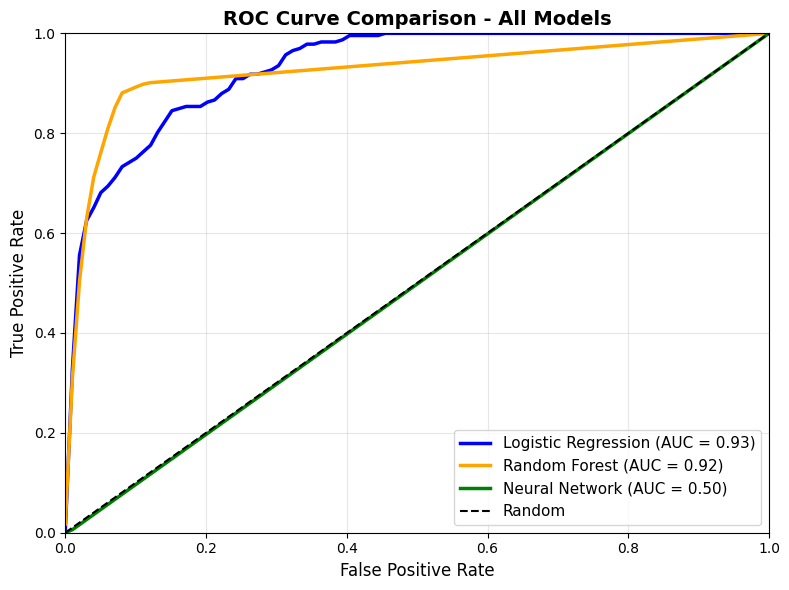

Mean AUCs:
Logistic Regression: 0.930
Random Forest: 0.922
Neural Network: 0.498


In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, auc
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# 5-fold CV setup
k = 5
skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

# Store results for plotting
model_names = ['Logistic Regression', 'Random Forest', 'Neural Network']
colors = ['blue', 'orange', 'green']
mean_fprs = {}
mean_tprs = {}
mean_aucs = {}

# === LOGISTIC REGRESSION ===
logreg = LogisticRegression(max_iter=1000)
fprs_lr, tprs_lr = [], []
for train_idx, test_idx in skf.split(X, y):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    logreg.fit(X_train, y_train)
    y_prob = logreg.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    fprs_lr.append(fpr)
    tprs_lr.append(tpr)

# Interpolate and average
mean_fpr = np.linspace(0, 1, 100)
tprs_interp = [interp1d(fpr, tpr, kind='linear', bounds_error=False, fill_value=(0, 1))(mean_fpr)
               for fpr, tpr in zip(fprs_lr, tprs_lr)]
mean_tpr = np.mean(tprs_interp, axis=0)
mean_auc = auc(mean_fpr, mean_tpr)
mean_fprs['Logistic Regression'] = mean_fpr
mean_tprs['Logistic Regression'] = mean_tpr
mean_aucs['Logistic Regression'] = mean_auc

# === RANDOM FOREST ===
rf = RandomForestClassifier(n_estimators=100, random_state=42)
fprs_rf, tprs_rf = [], []
for train_idx, test_idx in skf.split(X, y):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    rf.fit(X_train, y_train)
    y_prob = rf.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    fprs_rf.append(fpr)
    tprs_rf.append(tpr)

tprs_interp = [interp1d(fpr, tpr, kind='linear', bounds_error=False, fill_value=(0, 1))(mean_fpr)
               for fpr, tpr in zip(fprs_rf, tprs_rf)]
mean_tpr = np.mean(tprs_interp, axis=0)
mean_auc = auc(mean_fpr, mean_tpr)
mean_fprs['Random Forest'] = mean_fpr
mean_tprs['Random Forest'] = mean_tpr
mean_aucs['Random Forest'] = mean_auc

# === NEURAL NETWORK ===
fprs_nn, tprs_nn = [], []
for train_idx, test_idx in skf.split(X, y):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    nn = Sequential([Dense(64, activation='relu', input_dim=X.shape[1]),
                     Dense(1, activation='sigmoid')])
    nn.compile(optimizer='adam', loss='binary_crossentropy')
    nn.fit(X_train, y_train, epochs=10, batch_size=32, verbose=0)
    y_prob = nn.predict(X_test, verbose=0).ravel()
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    fprs_nn.append(fpr)
    tprs_nn.append(tpr)

tprs_interp = [interp1d(fpr, tpr, kind='linear', bounds_error=False, fill_value=(0, 1))(mean_fpr)
               for fpr, tpr in zip(fprs_nn, tprs_nn)]
mean_tpr = np.mean(tprs_interp, axis=0)
mean_auc = auc(mean_fpr, mean_tpr)
mean_fprs['Neural Network'] = mean_fpr
mean_tprs['Neural Network'] = mean_tpr
mean_aucs['Neural Network'] = mean_auc

# === PLOT ===
plt.figure(figsize=(8, 6))
for i, name in enumerate(model_names):
    plt.plot(mean_fprs[name], mean_tprs[name], color=colors[i], linewidth=2.5,
             label=f'{name} (AUC = {mean_aucs[name]:.2f})')

plt.plot([0, 1], [0, 1], color='black', linestyle='--', linewidth=1.5, label='Random')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curve Comparison - All Models', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Mean AUCs:")
for name in model_names:
    print(f"{name}: {mean_aucs[name]:.3f}")
